In [1]:
print("Hello Mars!")

Hello Mars!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("Numpy version:", np.__version__)
print("Pandas version:", pd.__version__)
print ("All libraries imported succesfully.")

Numpy version: 2.3.5
Pandas version: 2.3.3
All libraries imported succesfully.


# NASA MEDA — Initial Data Exploration

## Sol 1741: Calibrated TIRS Observations

Objective:
To understand the structure, variables, and quality
of the Martian environmental observations before analysis.

## 1. Loading the NASA MEDA Dataset

The calibrated TIRS observations from Perseverance's Sol 1741
will be imported into Python using the Pandas library.

Our objective is to convert the raw CSV file into a
structured DataFrame for further exploration.

In [3]:
file_path_1741 = "../data/raw/WE__1741___________CAL_TIRS________________P01.csv"
sol_1741 = pd.read_csv(file_path_1741)
print (type(sol_1741))

<class 'pandas.core.frame.DataFrame'>


## 2. Initial Dataset Inspection

Before performing any calculations, we need to understand
the structure and contents of our dataset.

We will examine its dimensions, column names, data types,
and the first few observations.

In [4]:
sol_1741.head() #printing everything from the 1st 5 rows in a tabular format to check visually

,SCLK,LMST,LTST,DOWNWARD_LW_IRRADIANCE,DOWNWARD_LW_IRRADIANCE_UNCERTAINTY,AIR_TEMP,AIR_TEMP_UNCERTAINTY,UPWARD_SW_IRRADIANCE,UPWARD_SW_IRRADIANCE_UNCERTAINTY,UPWARD_LW_IRRADIANCE,...,GROUND_TEMP,GROUND_TEMP_UNCERTAINTY,RSM_HEAD_OUTSIDE_TIRS_UPWARD_LOOKING_FOV,WHEEL_OUTSIDE_TIRS_DOWNWARD_LOOKING_FOV,SUN_OUTSIDE_TIRS_FOV,ROVER_LOW_TILT,TIRS_GROUND_FOOTPRINT_NOT_IN_SHADOW,ROVER_HGA_OFF,SKYCAM_OFF,ROVER_STILL
0,821450641,01741M00:00:00.819,1741 00:37:52,15.44,0.58,208.52,0.76,-0.17,0.09,30.86,...,201.51,0.43,0,NaN,1,1,1,NaN,NaN,1
1,821450642,01741M00:00:01.792,1741 00:37:53,15.41,0.58,208.39,0.76,-0.13,0.09,30.92,...,201.48,0.43,0,NaN,1,1,1,NaN,NaN,1
2,821450643,01741M00:00:02.766,1741 00:37:54,15.45,0.58,208.62,0.76,-0.17,0.09,30.86,...,201.50,0.43,0,NaN,1,1,1,NaN,NaN,1
3,821450644,01741M00:00:03.739,1741 00:37:55,15.41,0.58,208.43,0.76,-0.11,0.09,30.89,...,201.56,0.43,0,NaN,1,1,1,NaN,NaN,1
4,821450645,01741M00:00:04.712,1741 00:37:56,15.45,0.58,208.72,0.76,-0.20,0.09,30.85,...,201.49,0.43,0,NaN,1,1,1,NaN,NaN,1


In [5]:
sol_1741.shape #printing the size of the whole CSV file in (rows,columns) format

(88774, 21)

In [6]:
sol_1741.columns #printing all column headings to check all content types

Index(['SCLK', 'LMST', 'LTST', 'DOWNWARD_LW_IRRADIANCE',
       'DOWNWARD_LW_IRRADIANCE_UNCERTAINTY', 'AIR_TEMP',
       'AIR_TEMP_UNCERTAINTY', 'UPWARD_SW_IRRADIANCE',
       'UPWARD_SW_IRRADIANCE_UNCERTAINTY', 'UPWARD_LW_IRRADIANCE',
       'UPWARD_LW_IRRADIANCE_UNCERTAINTY', 'GROUND_TEMP',
       'GROUND_TEMP_UNCERTAINTY', 'RSM_HEAD_OUTSIDE_TIRS_UPWARD_LOOKING_FOV',
       'WHEEL_OUTSIDE_TIRS_DOWNWARD_LOOKING_FOV', 'SUN_OUTSIDE_TIRS_FOV',
       'ROVER_LOW_TILT', 'TIRS_GROUND_FOOTPRINT_NOT_IN_SHADOW',
       'ROVER_HGA_OFF', 'SKYCAM_OFF', 'ROVER_STILL'],
      dtype='object')

## 3. Examining Dataset Structure

We will inspect the dimensions, data types and
available observations to understand how the
NASA MEDA measurements are organised.

In [7]:
sol_1741.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88774 entries, 0 to 88773
Data columns (total 21 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   SCLK                                      88774 non-null  int64  
 1   LMST                                      88774 non-null  object 
 2   LTST                                      88774 non-null  object 
 3   DOWNWARD_LW_IRRADIANCE                    88774 non-null  float64
 4   DOWNWARD_LW_IRRADIANCE_UNCERTAINTY        88774 non-null  float64
 5   AIR_TEMP                                  88774 non-null  float64
 6   AIR_TEMP_UNCERTAINTY                      88774 non-null  float64
 7   UPWARD_SW_IRRADIANCE                      88774 non-null  float64
 8   UPWARD_SW_IRRADIANCE_UNCERTAINTY          88774 non-null  float64
 9   UPWARD_LW_IRRADIANCE                      88774 non-null  float64
 10  UPWARD_LW_IRRADIANCE_UNCERTAINTY  

In [8]:
sol_1741.describe()

,SCLK,DOWNWARD_LW_IRRADIANCE,DOWNWARD_LW_IRRADIANCE_UNCERTAINTY,AIR_TEMP,AIR_TEMP_UNCERTAINTY,UPWARD_SW_IRRADIANCE,UPWARD_SW_IRRADIANCE_UNCERTAINTY,UPWARD_LW_IRRADIANCE,UPWARD_LW_IRRADIANCE_UNCERTAINTY,GROUND_TEMP,GROUND_TEMP_UNCERTAINTY,RSM_HEAD_OUTSIDE_TIRS_UPWARD_LOOKING_FOV,WHEEL_OUTSIDE_TIRS_DOWNWARD_LOOKING_FOV,SUN_OUTSIDE_TIRS_FOV,ROVER_LOW_TILT,TIRS_GROUND_FOOTPRINT_NOT_IN_SHADOW,ROVER_HGA_OFF,SKYCAM_OFF,ROVER_STILL
count,8.877400e+04,88774.000000,88774.000000,88774.000000,88774.000000,88774.000000,88774.000000,88774.000000,88774.000000,88774.000000,88774.000000,88774.0,0.0,88774.000000,88774.0,88774.000000,0.0,0.0,88774.0
mean,8.214950e+08,17.717812,1.222656,221.157025,0.911642,22.471415,0.597479,65.318478,0.590251,225.855751,0.443472,0.0,NaN,0.936412,1.0,0.849505,NaN,NaN,1.0
std,2.562699e+04,3.203916,0.769685,13.364602,0.236477,29.431208,0.677042,44.962173,0.297561,29.325026,0.057247,0.0,NaN,0.244020,0.0,0.357557,NaN,NaN,0.0
min,8.214506e+08,13.010000,0.440000,199.590000,0.700000,-0.350000,0.090000,25.650000,0.300000,194.890000,0.330000,0.0,NaN,0.000000,1.0,0.000000,NaN,NaN,1.0
25%,8.214728e+08,14.700000,0.550000,208.130000,0.750000,-0.030000,0.090000,30.260000,0.340000,200.830000,0.410000,0.0,NaN,1.000000,1.0,1.000000,NaN,NaN,1.0
50%,8.214950e+08,17.420000,0.820000,220.690000,0.790000,0.590000,0.110000,41.210000,0.450000,212.760000,0.430000,0.0,NaN,1.000000,1.0,1.000000,NaN,NaN,1.0
75%,8.215172e+08,20.460000,2.060000,232.050000,1.010000,52.000000,1.270000,97.620000,0.800000,252.440000,0.460000,0.0,NaN,1.000000,1.0,1.000000,NaN,NaN,1.0
max,8.215394e+08,24.220000,2.530000,249.200000,1.790000,76.990000,1.870000,158.500000,1.290000,279.800000,0.610000,0.0,NaN,1.000000,1.0,1.000000,NaN,NaN,1.0


## 5. Temperature Distribution

We will examine the statistical distribution of
air and ground temperatures recorded by MEDA TIRS.

Our objective is to understand their ranges,
central tendencies and differences.

In [9]:
print ("Air Temperature:")
print (sol_1741["AIR_TEMP"].describe())
print ("\nGround Temperature:")
print (sol_1741["GROUND_TEMP"].describe())

Air Temperature:
count    88774.000000
mean       221.157025
std         13.364602
min        199.590000
25%        208.130000
50%        220.690000
75%        232.050000
max        249.200000
Name: AIR_TEMP, dtype: float64

Ground Temperature:
count    88774.000000
mean       225.855751
std         29.325026
min        194.890000
25%        200.830000
50%        212.760000
75%        252.440000
max        279.800000
Name: GROUND_TEMP, dtype: float64


## 6. Temperature Conversion

For easier physical interpretation, we will convert
the air and ground temperatures from Kelvin to Celsius.

The original NASA measurements will remain unchanged.

In [10]:
sol_1741["AIR_TEMP_C"] = sol_1741["AIR_TEMP"] - 273.15
sol_1741["GROUND_TEMP_C"] = sol_1741["GROUND_TEMP"] - 273.15
sol_1741[["AIR_TEMP_C", "GROUND_TEMP_C"]].describe()

,AIR_TEMP_C,GROUND_TEMP_C
count,88774.000000,88774.000000
mean,-51.992975,-47.294249
std,13.364602,29.325026
min,-73.560000,-78.260000
25%,-65.020000,-72.320000
50%,-52.460000,-60.390000
75%,-41.100000,-20.710000
max,-23.950000,6.650000


In [11]:
print(sol_1741[["SCLK", "LMST", "LTST", "AIR_TEMP_C", "GROUND_TEMP_C"]].head(10))
sol_1741[["SCLK", "LMST", "LTST", "AIR_TEMP_C", "GROUND_TEMP_C"]].tail(10)

        SCLK                LMST           LTST  AIR_TEMP_C  GROUND_TEMP_C
0  821450641  01741M00:00:00.819  1741 00:37:52      -64.63         -71.64
1  821450642  01741M00:00:01.792  1741 00:37:53      -64.76         -71.67
2  821450643  01741M00:00:02.766  1741 00:37:54      -64.53         -71.65
3  821450644  01741M00:00:03.739  1741 00:37:55      -64.72         -71.59
4  821450645  01741M00:00:04.712  1741 00:37:56      -64.43         -71.66
5  821450646  01741M00:00:05.685  1741 00:37:57      -64.40         -71.59
6  821450647  01741M00:00:06.659  1741 00:37:58      -65.05         -71.67
7  821450648  01741M00:00:07.632  1741 00:37:59      -63.90         -71.63
8  821450649  01741M00:00:08.605  1741 00:38:00      -64.56         -71.64
9  821450650  01741M00:00:09.578  1741 00:38:01      -64.01         -71.60


,SCLK,LMST,LTST,AIR_TEMP_C,GROUND_TEMP_C
88764,821539405,01741M23:59:50.563,1742 00:37:32,-62.95,-71.47
88765,821539406,01741M23:59:51.536,1742 00:37:33,-62.86,-71.49
88766,821539407,01741M23:59:52.509,1742 00:37:34,-62.63,-71.45
88767,821539408,01741M23:59:53.482,1742 00:37:35,-63.12,-71.49
88768,821539409,01741M23:59:54.456,1742 00:37:36,-62.97,-71.42
88769,821539410,01741M23:59:55.429,1742 00:37:37,-63.21,-71.48
88770,821539411,01741M23:59:56.402,1742 00:37:38,-62.96,-71.49
88771,821539412,01741M23:59:57.375,1742 00:37:39,-63.28,-71.46
88772,821539413,01741M23:59:58.349,1742 00:37:40,-62.89,-71.47
88773,821539414,01741M23:59:59.322,1742 00:37:41,-63.09,-71.49


## 7. Exploring the daily temperature cycle
Although the LTST is the True Local Standard Time (based on Sun's actual position in the sky), we will still use the LMST here (the Mean Standard Time that is according to a hypothetical constant rate of Sun's movement) for our convenience to plot our temperature curve throughout the Sol 1741.

                     LMST  LMST_HOURS
88769  01741M23:59:55.429   23.998730
88770  01741M23:59:56.402   23.999001
88771  01741M23:59:57.375   23.999271
88772  01741M23:59:58.349   23.999541
88773  01741M23:59:59.322   23.999812


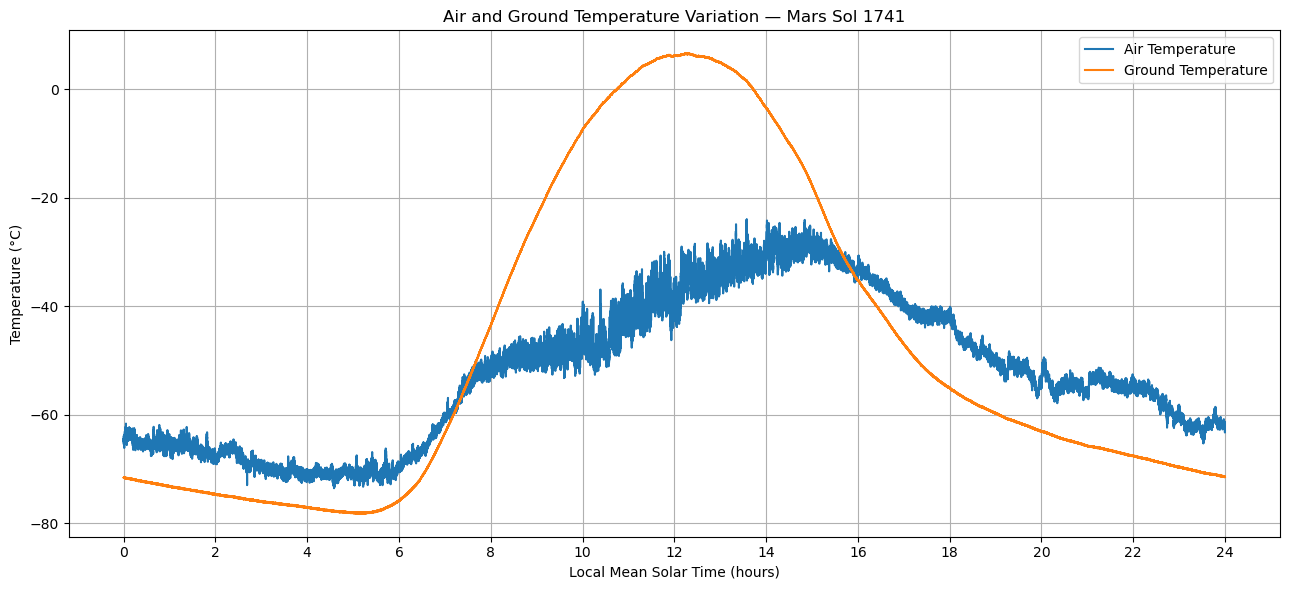

AIR TEMPERATURE
Maximum: -23.94999999999999 °C
Time: 01741M13:34:45.322

Minimum: -73.55999999999997 °C
Time: 01741M04:35:02.307

GROUND TEMPERATURE
Maximum: 6.650000000000034 °C
Time: 01741M12:14:54.976

Minimum: -78.25999999999999 °C
Time: 01741M05:13:22.102


In [12]:
# Converting LMST into decimal hours for Matplotlib's easy understanding 
sol_1741["LMST_HOURS"] = (
    pd.to_timedelta(sol_1741["LMST"].str.split("M").str[1])
    .dt.total_seconds() / 3600
)

# Check the converted values
print(sol_1741[["LMST", "LMST_HOURS"]].tail())

# Plotting Time-Temp graph
plt.figure(figsize=(13, 6))

plt.plot(sol_1741["LMST_HOURS"], sol_1741["AIR_TEMP_C"], label="Air Temperature")
plt.plot(sol_1741["LMST_HOURS"], sol_1741["GROUND_TEMP_C"], label="Ground Temperature")

plt.xlabel("Local Mean Solar Time (hours)")
plt.ylabel("Temperature (°C)")
plt.title("Air and Ground Temperature Variation — Mars Sol 1741")

plt.xticks(range(0, 25, 2))
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()



# Find temperature extremes
air_max = sol_1741["AIR_TEMP_C"].idxmax()
air_min = sol_1741["AIR_TEMP_C"].idxmin()

ground_max = sol_1741["GROUND_TEMP_C"].idxmax()
ground_min = sol_1741["GROUND_TEMP_C"].idxmin()

# Display the results
print("AIR TEMPERATURE")
print("Maximum:", sol_1741.loc[air_max, "AIR_TEMP_C"], "°C")
print("Time:", sol_1741.loc[air_max, "LMST"])

print("\nMinimum:", sol_1741.loc[air_min, "AIR_TEMP_C"], "°C")
print("Time:", sol_1741.loc[air_min, "LMST"])

print("\nGROUND TEMPERATURE")
print("Maximum:", sol_1741.loc[ground_max, "GROUND_TEMP_C"], "°C")
print("Time:", sol_1741.loc[ground_max, "LMST"])

print("\nMinimum:", sol_1741.loc[ground_min, "GROUND_TEMP_C"], "°C")
print("Time:", sol_1741.loc[ground_min, "LMST"])

## 8. Ground-Air Temperature Difference

                 LMST  AIR_TEMP_C  GROUND_TEMP_C  TEMP_DIFFERENCE
0  01741M00:00:00.819      -64.63         -71.64            -7.01
1  01741M00:00:01.792      -64.76         -71.67            -6.91
2  01741M00:00:02.766      -64.53         -71.65            -7.12
3  01741M00:00:03.739      -64.72         -71.59            -6.87
4  01741M00:00:04.712      -64.43         -71.66            -7.23
5  01741M00:00:05.685      -64.40         -71.59            -7.19
6  01741M00:00:06.659      -65.05         -71.67            -6.62
7  01741M00:00:07.632      -63.90         -71.63            -7.73
8  01741M00:00:08.605      -64.56         -71.64            -7.08
9  01741M00:00:09.578      -64.01         -71.60            -7.59


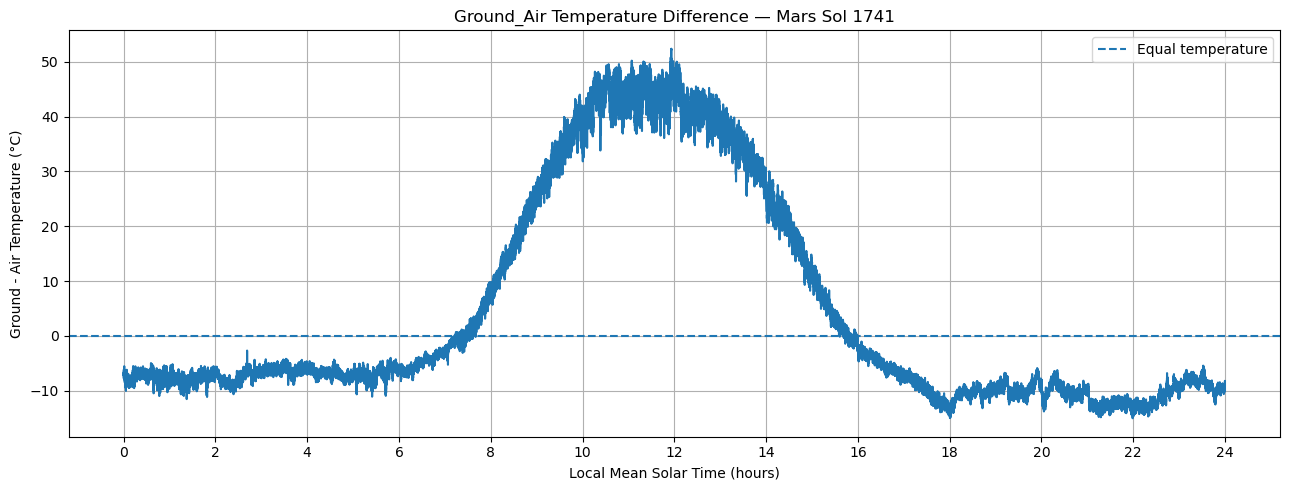

In [13]:
# Calculate the simultaneous ground-air temperature difference
sol_1741["TEMP_DIFFERENCE"] = sol_1741["GROUND_TEMP_C"] - sol_1741["AIR_TEMP_C"]

# Inspect the new column
print(sol_1741[["LMST", "AIR_TEMP_C", "GROUND_TEMP_C", "TEMP_DIFFERENCE"]].head(10))



plt.figure(figsize=(13, 5))

plt.plot(sol_1741["LMST_HOURS"], sol_1741["TEMP_DIFFERENCE"])

plt.axhline(y=0, linestyle="--", label="Equal temperature")

plt.xlabel("Local Mean Solar Time (hours)")
plt.ylabel("Ground - Air Temperature (°C)")
plt.title("Ground_Air Temperature Difference — Mars Sol 1741")

plt.xticks(range(0, 25, 2))
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Maximum ground-air temperature difference:
LMST               01741M11:55:57.244
TEMP_DIFFERENCE                 52.35
Name: 44137, dtype: object

Minimum ground-air temperature difference:
LMST               01741M21:59:16.380
TEMP_DIFFERENCE                 -15.0
Name: 81331, dtype: object
LMST_HOURS
0     -7.476245
1     -7.746015
2     -7.579429
3     -6.121665
4     -6.816434
5     -6.875742
6     -4.945101
7      1.529127
8     16.649954
9     33.468175
10    43.366283
11    44.502252
12    41.695996
13    33.821403
14    19.318927
15     3.802858
16    -4.936937
17   -10.048919
18   -10.572106
19    -9.545982
20    -9.968121
21   -12.470881
22   -11.520638
23    -8.768510
Name: TEMP_DIFFERENCE, dtype: float64


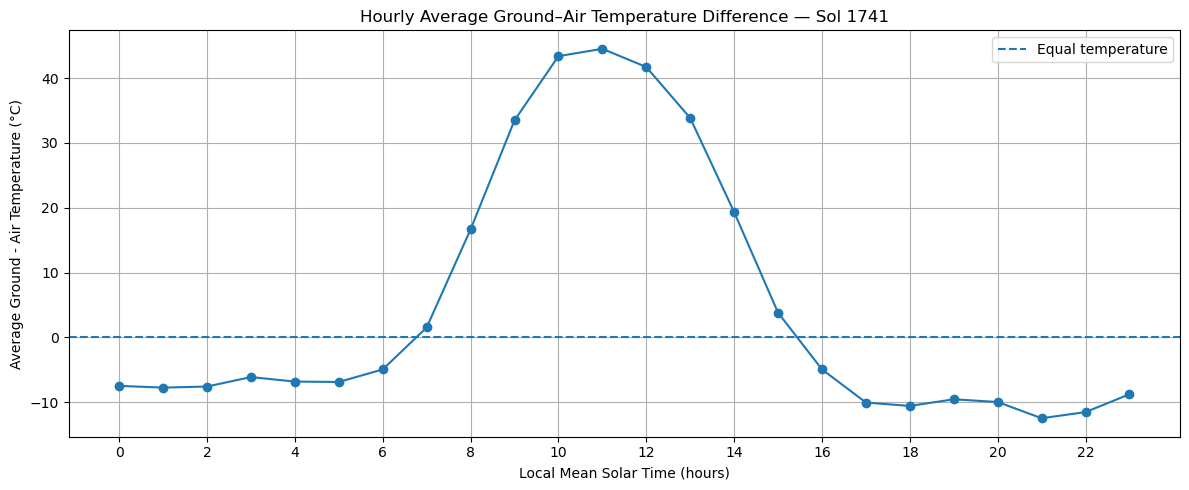

In [14]:
# Find maximum and minimum temperature differences
max_diff = sol_1741["TEMP_DIFFERENCE"].idxmax()
min_diff = sol_1741["TEMP_DIFFERENCE"].idxmin()

print("Maximum ground-air temperature difference:")
print(sol_1741.loc[max_diff, ["LMST", "TEMP_DIFFERENCE"]])

print("\nMinimum ground-air temperature difference:")
print(sol_1741.loc[min_diff, ["LMST", "TEMP_DIFFERENCE"]])


# Group observations by their LMST hour
hourly_difference = sol_1741.groupby(
    sol_1741["LMST_HOURS"].astype(int)
)["TEMP_DIFFERENCE"].mean()

print(hourly_difference)



plt.figure(figsize=(12, 5))

plt.plot(hourly_difference.index, hourly_difference.values, marker="o")

plt.axhline(y=0, linestyle="--", label="Equal temperature")

plt.xlabel("Local Mean Solar Time (hours)")
plt.ylabel("Average Ground - Air Temperature (°C)")
plt.title("Hourly Average Ground–Air Temperature Difference — Sol 1741")

plt.xticks(range(0, 24, 2))
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

## 9. Hourly Temperature Profiles

            AIR_TEMP_C  GROUND_TEMP_C
LMST_HOURS                           
0           -64.946683     -72.422928
1           -66.209581     -73.955596
2           -67.768488     -75.347918
3           -70.428724     -76.550389
4           -70.848527     -77.664961
5           -70.652160     -77.527902
6           -65.805645     -70.750746
7           -55.250760     -53.721633
8           -49.704950     -33.054996
9           -48.498381     -15.030205
10          -45.673979      -2.307697
11          -39.700124       4.802128
12          -35.652914       6.043082
13          -32.204636       1.616767
14          -29.344682     -10.025756
15          -30.982593     -27.179735
16          -36.145207     -41.082144
17          -41.486242     -51.535161
18          -47.038283     -57.610389
19          -51.911850     -61.457831
20          -54.490557     -64.458678
21          -54.160689     -66.631571
22          -57.107762     -68.628400
23          -61.822230     -70.590741


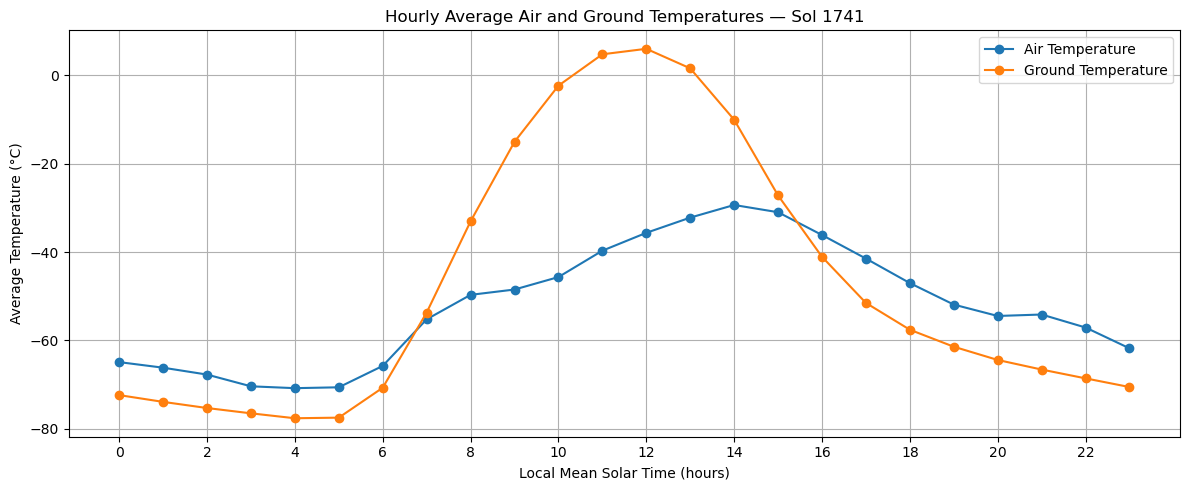

In [15]:
# Calculate hourly average temperatures
hourly_temps = sol_1741.groupby(
    sol_1741["LMST_HOURS"].astype(int)
)[["AIR_TEMP_C", "GROUND_TEMP_C"]].mean()

print(hourly_temps)



plt.figure(figsize=(12, 5))

plt.plot(hourly_temps.index, hourly_temps["AIR_TEMP_C"],
         marker="o", label="Air Temperature")

plt.plot(hourly_temps.index, hourly_temps["GROUND_TEMP_C"],
         marker="o", label="Ground Temperature")

plt.xlabel("Local Mean Solar Time (hours)")
plt.ylabel("Average Temperature (°C)")
plt.title("Hourly Average Air and Ground Temperatures — Sol 1741")

plt.xticks(range(0, 24, 2))
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

## 10. Data Quality Check for each Hour

In [16]:
# First-pass observation quality screening for Sol 1741

sol_1741["QUALITY_OK"] = (
    (sol_1741["ROVER_LOW_TILT"] == 1)
    & (sol_1741["ROVER_STILL"] == 1)
    & (sol_1741["TIRS_GROUND_FOOTPRINT_NOT_IN_SHADOW"] == 1)
    & (sol_1741["SUN_OUTSIDE_TIRS_FOV"] == 1)
)

# Count observations passing the screen in each hour
quality_by_hour = sol_1741.groupby(
    sol_1741["LMST_HOURS"].astype(int)
)["QUALITY_OK"].agg(["sum", "count"])

print(quality_by_hour)


             sum  count
LMST_HOURS             
0           3699   3699
1           3699   3699
2           3698   3698
3           3699   3699
4           3699   3699
5           3699   3699
6           1576   3699
7            177   3699
8           3699   3699
9           3699   3699
10          3699   3699
11          3699   3699
12          3699   3699
13           574   3699
14             0   3699
15             0   3699
16           862   3699
17          3699   3699
18          3699   3699
19          3698   3698
20          3699   3699
21          3699   3699
22          3699   3699
23          3699   3699


In [17]:
flags = [
    "ROVER_LOW_TILT",
    "ROVER_STILL",
    "TIRS_GROUND_FOOTPRINT_NOT_IN_SHADOW",
    "SUN_OUTSIDE_TIRS_FOV"
]

# Fraction of observations marked 1 for each condition, by hour
flag_summary = sol_1741.groupby(
    sol_1741["LMST_HOURS"].astype(int)
)[flags].mean()

print(flag_summary.loc[6:17].round(2))

            ROVER_LOW_TILT  ROVER_STILL  TIRS_GROUND_FOOTPRINT_NOT_IN_SHADOW  \
LMST_HOURS                                                                     
6                      1.0          1.0                                 1.00   
7                      1.0          1.0                                 1.00   
8                      1.0          1.0                                 1.00   
9                      1.0          1.0                                 1.00   
10                     1.0          1.0                                 1.00   
11                     1.0          1.0                                 1.00   
12                     1.0          1.0                                 1.00   
13                     1.0          1.0                                 0.16   
14                     1.0          1.0                                 0.00   
15                     1.0          1.0                                 0.00   
16                     1.0          1.0 

## 11. Reflected solar radiation and Ground Thermal Response

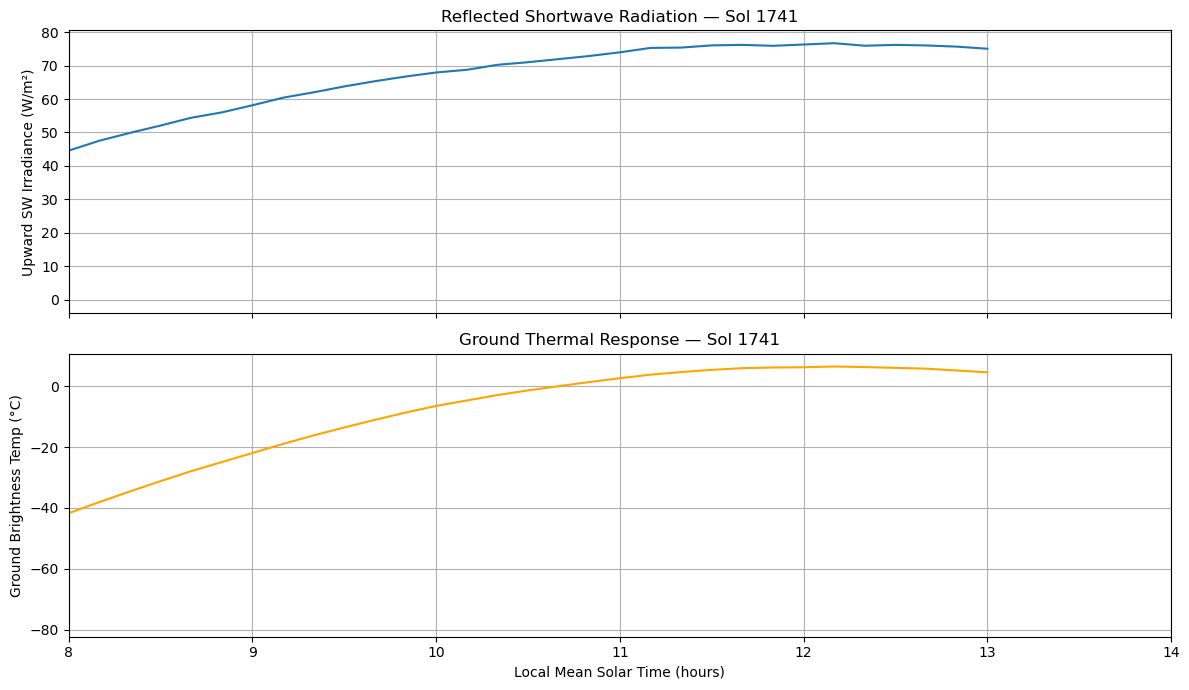

In [18]:
# Select observations passing our preliminary quality screening
good = sol_1741[sol_1741["QUALITY_OK"]].copy()

# Divide the sol into 10-minute time bins
good["BIN_10MIN"] = (good["LMST_HOURS"] * 6).astype(int)

# Calculate 10-minute averages and observation counts
ten_min = good.groupby("BIN_10MIN").agg(
    sw=("UPWARD_SW_IRRADIANCE", "mean"),
    ground=("GROUND_TEMP_C", "mean"),
    count=("UPWARD_SW_IRRADIANCE", "count")
).reindex(range(144))

# Require at least 300 observations per 10-minute bin
ten_min.loc[ten_min["count"] < 300, ["sw", "ground"]] = float("nan")

ten_min["LMST_HOURS"] = ten_min.index / 6

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].plot(ten_min["LMST_HOURS"], ten_min["sw"])
ax[0].set_ylabel("Upward SW Irradiance (W/m²)")
ax[0].set_title("Reflected Shortwave Radiation — Sol 1741")
ax[0].grid(True)

ax[1].plot(ten_min["LMST_HOURS"], ten_min["ground"],
           color="orange")
ax[1].set_ylabel("Ground Brightness Temp (°C)")
ax[1].set_xlabel("Local Mean Solar Time (hours)")
ax[1].set_title("Ground Thermal Response — Sol 1741")
ax[1].grid(True)

plt.xlim(8, 14)
plt.xticks(range(8, 15))
plt.tight_layout()
plt.show()

In [19]:
# Identify the 10-minute bins with maximum average values
sw_peak_bin = ten_min["sw"].idxmax()
ground_peak_bin = ten_min["ground"].idxmax()

# Calculate the difference between their peak-bin start times
delay_minutes = (ground_peak_bin - sw_peak_bin) * 10

print("Upward SW irradiance:")
print("Peak 10-minute average:", round(ten_min.loc[sw_peak_bin, "sw"], 2), "W/m²")
print("Peak LMST bin:", f"{sw_peak_bin//6:02d}:{(sw_peak_bin%6)*10:02d}")

print("\nGround brightness temperature:")
print("Peak 10-minute average:", round(ten_min.loc[ground_peak_bin, "ground"], 2), "°C")
print("Peak LMST bin:", f"{ground_peak_bin//6:02d}:{(ground_peak_bin%6)*10:02d}")

print("\nGround peak minus SW peak:", delay_minutes, "minutes")

Upward SW irradiance:
Peak 10-minute average: 76.67 W/m²
Peak LMST bin: 12:10

Ground brightness temperature:
Peak 10-minute average: 6.53 °C
Peak LMST bin: 12:10

Ground peak minus SW peak: 0 minutes


## 12. Peak Timing Relative to True Solar Noon

In [20]:
# Load Sol 1750
sol1750 = pd.read_csv(
    "../data/raw/WE__1750___________CAL_TIRS________________P01.csv"
)

# Extract LMST in decimal hours
sol1750["LMST_HOURS"] = (
    pd.to_timedelta(sol1750["LMST"].str.split("M").str[1])
    .dt.total_seconds() / 3600
)

# Apply the same observation-condition screening
sol1750["QUALITY_OK"] = (
    (sol1750["ROVER_LOW_TILT"] == 1)
    & (sol1750["ROVER_STILL"] == 1)
    & (sol1750["TIRS_GROUND_FOOTPRINT_NOT_IN_SHADOW"] == 1)
    & (sol1750["SUN_OUTSIDE_TIRS_FOV"] == 1)
)

good1750 = sol1750[sol1750["QUALITY_OK"]].copy()

# Group into 10-minute intervals
good1750["BIN_10MIN"] = (good1750["LMST_HOURS"] * 6).astype(int)

ten1750 = good1750.groupby("BIN_10MIN").agg(
    sw=("UPWARD_SW_IRRADIANCE", "mean"),
    ground=("GROUND_TEMP", "mean"),
    count=("UPWARD_SW_IRRADIANCE", "count")
).reindex(range(144))

ten1750.loc[ten1750["count"] < 300, ["sw", "ground"]] = float("nan")

# Compare peak times for both sols

for sol, data, summary in [
    (1741, sol_1741, ten_min),
    (1750, sol1750, ten1750)
]:
    print(f"\nSOL {sol}")

    for name, column in [
        ("Upward SW", "sw"),
        ("Ground Temperature", "ground")
    ]:
        peak_bin = summary[column].idxmax()

        matching_rows = data[
            data["QUALITY_OK"] &
            ((data["LMST_HOURS"] * 6).astype(int) == peak_bin)
        ]

        ltst = pd.to_timedelta(
            matching_rows["LTST"].str.split().str[-1]
        ).median()

        minutes_after_noon = (
            ltst - pd.Timedelta(hours=12)
        ).total_seconds() / 60

        print(name)
        print("LTST:", ltst)
        print("Minutes after solar noon:", round(minutes_after_noon, 1))


SOL 1741
Upward SW
LTST: 0 days 12:52:46
Minutes after solar noon: 52.8
Ground Temperature
LTST: 0 days 12:52:46
Minutes after solar noon: 52.8

SOL 1750
Upward SW
LTST: 0 days 12:50:59
Minutes after solar noon: 51.0
Ground Temperature
LTST: 0 days 13:00:58.500000
Minutes after solar noon: 61.0


## 13. Cross-Sol Midday Radiative and Thermal Comparison

In [21]:
# Compare measurements in the same LTST interval

for sol, data in [(1741, sol_1741), (1750, sol1750)]:

    ltst = pd.to_timedelta(
        data["LTST"].str.split().str[-1]
    )

    midday = data[
        data["QUALITY_OK"]
        & ltst.between(
            pd.Timedelta("12:30:00"),
            pd.Timedelta("13:30:00")
        )
    ]

    print(f"\nSOL {sol}")
    print("Valid observations:", len(midday))

    print("Mean upward SW:",
          round(midday["UPWARD_SW_IRRADIANCE"].mean(), 2), "W/m²")

    print("Mean upward LW:",
          round(midday["UPWARD_LW_IRRADIANCE"].mean(), 2), "W/m²")

    print("Mean ground brightness temperature:",
          round(midday["GROUND_TEMP"].mean() - 273.15, 2), "°C")


SOL 1741
Valid observations: 3700
Mean upward SW: 76.14 W/m²
Mean upward LW: 157.06 W/m²
Mean ground brightness temperature: 6.18 °C

SOL 1750
Valid observations: 3701
Mean upward SW: 72.56 W/m²
Mean upward LW: 137.54 W/m²
Mean ground brightness temperature: -1.66 °C


## 14. Measurement Uncertainty and Variability

In [22]:
for sol, data in [(1741, sol_1741), (1750, sol1750)]:

    # Convert LTST to a time quantity
    ltst = pd.to_timedelta(
        data["LTST"].str.split().str[-1]
    )

    # Select our previously used midday interval
    midday = data[
        data["QUALITY_OK"]
        & (ltst >= pd.Timedelta("12:30:00"))
        & (ltst < pd.Timedelta("13:30:00"))
    ]

    print(f"\nSOL {sol}")
    print("Number of observations:", len(midday))

    print("\nUpward LW irradiance:")
    print("Mean:", round(midday["UPWARD_LW_IRRADIANCE"].mean(), 2), "W/m²")
    print("Mean reported uncertainty:",
          round(midday["UPWARD_LW_IRRADIANCE_UNCERTAINTY"].mean(), 2),
          "W/m²")

    print("\nGround brightness temperature:")
    print("Mean:", round(midday["GROUND_TEMP"].mean() - 273.15, 2), "°C")
    print("Mean reported uncertainty:",
          round(midday["GROUND_TEMP_UNCERTAINTY"].mean(), 2),
          "K")

    for sol, data in [(1741, sol_1741), (1750, sol1750)]:

     ltst = pd.to_timedelta(
        data["LTST"].str.split().str[-1]
    )

    mask = (
        data["QUALITY_OK"]
        & (ltst >= pd.Timedelta("12:30:00"))
        & (ltst < pd.Timedelta("13:30:00"))
    )

    midday = data.loc[mask].copy()

    # Assign each observation to a 10-minute LTST interval
    midday["TIME_BIN"] = ltst[mask].dt.floor("10min")

    # Calculate average measurements for each interval
    binned = midday.groupby("TIME_BIN").agg(
        LW_MEAN=("UPWARD_LW_IRRADIANCE", "mean"),
        GROUND_MEAN=("GROUND_TEMP", "mean"),
        COUNT=("GROUND_TEMP", "count")
    )

    binned["GROUND_MEAN"] -= 273.15

    print(f"\nSOL {sol}")
    print(binned.round(2))

    # Sol 1741: 10-minute averages between 12:30 and 13:30 LTST

ltst_1741 = pd.to_timedelta(
    sol_1741["LTST"].str.split().str[-1]
)

mask_1741 = (
    sol_1741["QUALITY_OK"]
    & (ltst_1741 >= pd.Timedelta("12:30:00"))
    & (ltst_1741 < pd.Timedelta("13:30:00"))
)

midday_1741 = sol_1741.loc[mask_1741].copy()

midday_1741["TIME_BIN"] = (
    ltst_1741[mask_1741].dt.floor("10min")
)

binned_1741 = midday_1741.groupby("TIME_BIN").agg(
    LW_MEAN=("UPWARD_LW_IRRADIANCE", "mean"),
    GROUND_MEAN=("GROUND_TEMP", "mean"),
    COUNT=("GROUND_TEMP", "count")
)

binned_1741["GROUND_MEAN"] -= 273.15

print("SOL 1741")
print(binned_1741.round(2))


SOL 1741
Number of observations: 3699

Upward LW irradiance:
Mean: 157.06 W/m²
Mean reported uncertainty: 1.23 W/m²

Ground brightness temperature:
Mean: 6.18 °C
Mean reported uncertainty: 0.47 K

SOL 1750
                 LW_MEAN  GROUND_MEAN  COUNT
TIME_BIN                                    
0 days 12:30:00   136.54        -2.05    617
0 days 12:40:00   137.68        -1.58    617
0 days 12:50:00   138.26        -1.35    616
0 days 13:00:00   138.29        -1.36    617
0 days 13:10:00   137.62        -1.63    616
0 days 13:20:00   136.85        -1.97    617

SOL 1750
Number of observations: 3700

Upward LW irradiance:
Mean: 137.54 W/m²
Mean reported uncertainty: 1.2 W/m²

Ground brightness temperature:
Mean: -1.66 °C
Mean reported uncertainty: 0.5 K

SOL 1750
                 LW_MEAN  GROUND_MEAN  COUNT
TIME_BIN                                    
0 days 12:30:00   136.54        -2.05    617
0 days 12:40:00   137.68        -1.58    617
0 days 12:50:00   138.26        -1.35    616
0 

## 15. Final Observation Summary

In [23]:
# Convert Sol 1750 temperatures from Kelvin to Celsius

sol1750["AIR_TEMP_C"] = sol1750["AIR_TEMP"] - 273.15
sol1750["GROUND_TEMP_C"] = sol1750["GROUND_TEMP"] - 273.15

# Verify the new columns
print(sol1750[[
    "AIR_TEMP", "AIR_TEMP_C",
    "GROUND_TEMP", "GROUND_TEMP_C"
]].head())

   AIR_TEMP  AIR_TEMP_C  GROUND_TEMP  GROUND_TEMP_C
0    202.61      -70.54       201.24         -71.91
1    202.89      -70.26       201.22         -71.93
2    203.44      -69.71       201.23         -71.92
3    202.94      -70.21       201.24         -71.91
4    202.62      -70.53       201.24         -71.91


In [24]:
def make_ten_min_summary(df):
    df_good = df[df["QUALITY_OK"]].copy()

    df_good["BIN_10MIN"] = (df_good["LMST_HOURS"] * 6).astype(int)

    summary = df_good.groupby("BIN_10MIN").agg(
        AIR_TEMP_C=("AIR_TEMP_C", "mean"),
        GROUND_TEMP_C=("GROUND_TEMP_C", "mean"),
        UPWARD_SW_IRRADIANCE=("UPWARD_SW_IRRADIANCE", "mean"),
        UPWARD_LW_IRRADIANCE=("UPWARD_LW_IRRADIANCE", "mean"),
        COUNT=("LMST_HOURS", "count")
    ).reindex(range(144))

    # Keep only bins with enough observations
    summary.loc[summary["COUNT"] < 300, [
        "AIR_TEMP_C",
        "GROUND_TEMP_C",
        "UPWARD_SW_IRRADIANCE",
        "UPWARD_LW_IRRADIANCE"
    ]] = float("nan")

    summary["LMST_HOURS"] = summary.index / 6
    return summary

ten1741 = make_ten_min_summary(sol_1741)
ten1750 = make_ten_min_summary(sol1750)

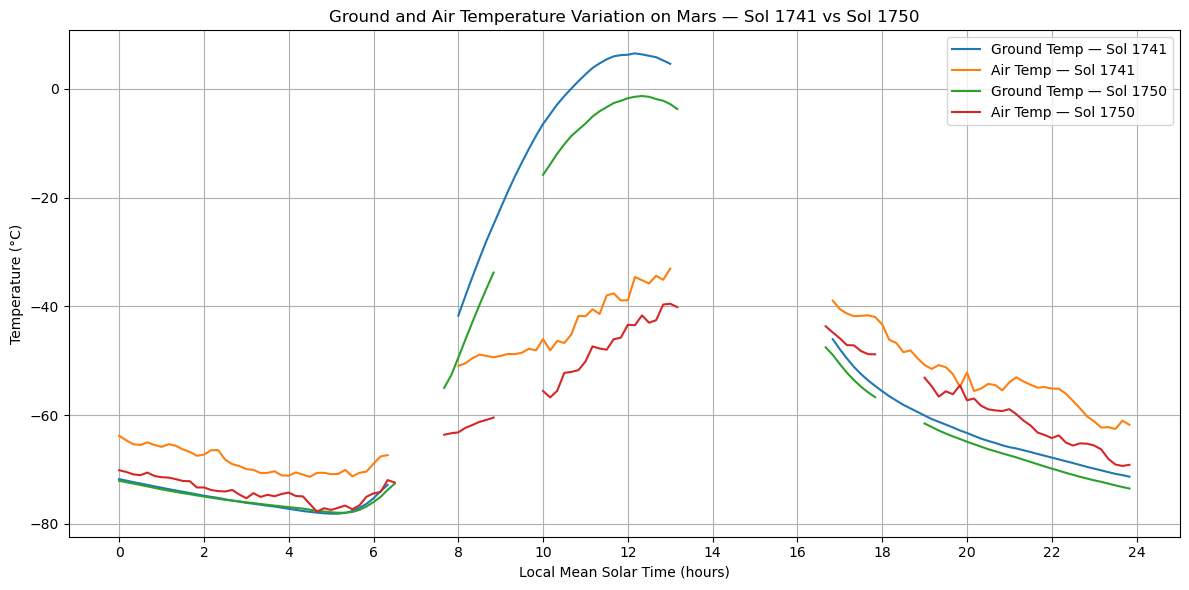

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(ten1741["LMST_HOURS"], ten1741["GROUND_TEMP_C"], label="Ground Temp — Sol 1741")
plt.plot(ten1741["LMST_HOURS"], ten1741["AIR_TEMP_C"], label="Air Temp — Sol 1741")

plt.plot(ten1750["LMST_HOURS"], ten1750["GROUND_TEMP_C"], label="Ground Temp — Sol 1750")
plt.plot(ten1750["LMST_HOURS"], ten1750["AIR_TEMP_C"], label="Air Temp — Sol 1750")

plt.xlabel("Local Mean Solar Time (hours)")
plt.ylabel("Temperature (°C)")
plt.title("Ground and Air Temperature Variation on Mars — Sol 1741 vs Sol 1750")
plt.xticks(range(0, 25, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

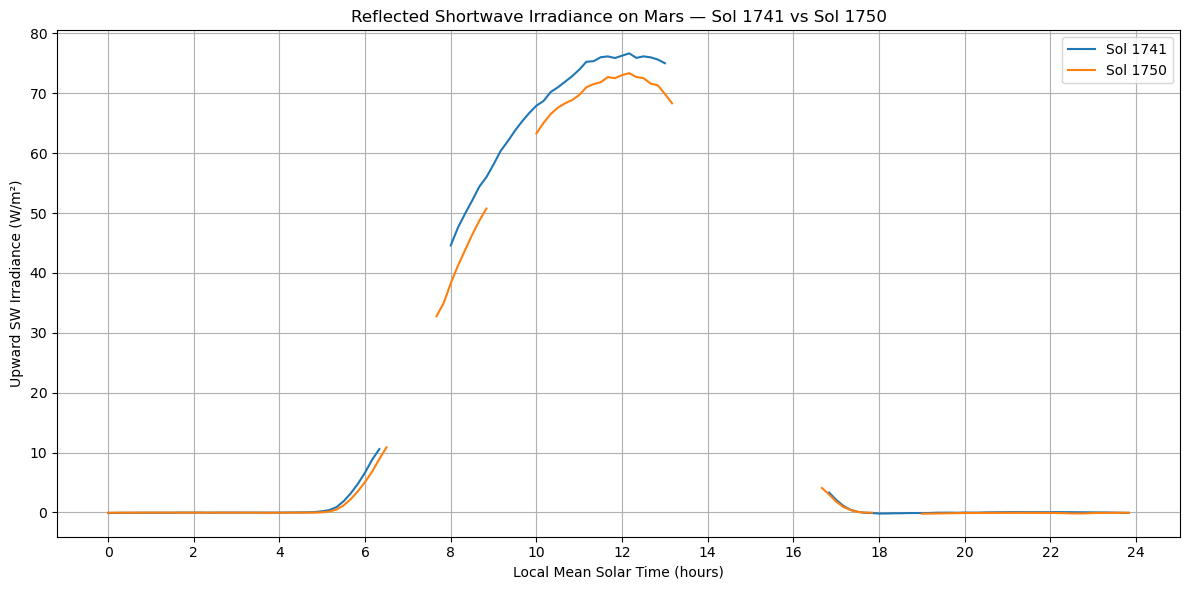

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(ten1741["LMST_HOURS"], ten1741["UPWARD_SW_IRRADIANCE"], label="Sol 1741")
plt.plot(ten1750["LMST_HOURS"], ten1750["UPWARD_SW_IRRADIANCE"], label="Sol 1750")

plt.xlabel("Local Mean Solar Time (hours)")
plt.ylabel("Upward SW Irradiance (W/m²)")
plt.title("Reflected Shortwave Irradiance on Mars — Sol 1741 vs Sol 1750")
plt.xticks(range(0, 25, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

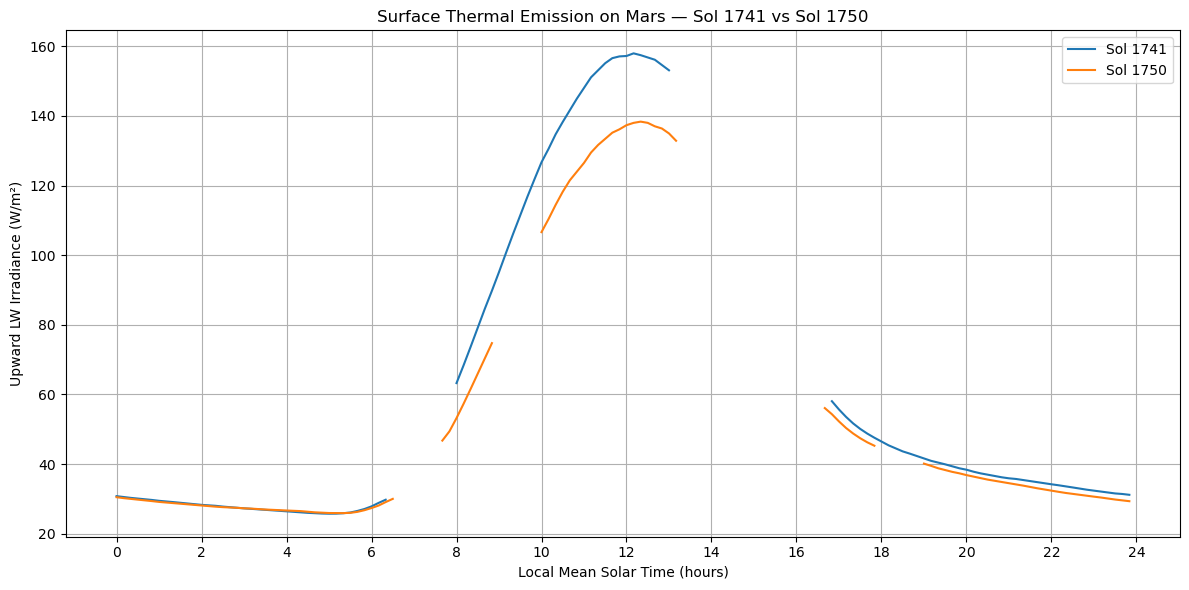

In [27]:
plt.figure(figsize=(12, 6))

plt.plot(ten1741["LMST_HOURS"], ten1741["UPWARD_LW_IRRADIANCE"], label="Sol 1741")
plt.plot(ten1750["LMST_HOURS"], ten1750["UPWARD_LW_IRRADIANCE"], label="Sol 1750")

plt.xlabel("Local Mean Solar Time (hours)")
plt.ylabel("Upward LW Irradiance (W/m²)")
plt.title("Surface Thermal Emission on Mars — Sol 1741 vs Sol 1750")
plt.xticks(range(0, 25, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
comparison_table = pd.DataFrame({
    "Measurement": [
        "Peak reflected SW (10-min avg)",
        "Peak SW time (LTST)",
        "Peak ground temp (10-min avg)",
        "Peak ground temp time (LTST)",
        "Midday mean upward LW (12:30–13:30 LTST)",
        "Midday mean ground temp"
    ],
    "Sol 1741": [
        "76.67 W/m²",
        "12:52:46",
        "6.53 °C",
        "12:52:46",
        "157.06 W/m²",
        "6.18 °C"
    ],
    "Sol 1750": [
        "73.36 W/m²",
        "12:50:59",
        "-1.32 °C",
        "13:00:58",
        "137.54 W/m²",
        "-1.66 °C"
    ]
})

print(comparison_table)

                                Measurement     Sol 1741     Sol 1750
0            Peak reflected SW (10-min avg)   76.67 W/m²   73.36 W/m²
1                       Peak SW time (LTST)     12:52:46     12:50:59
2             Peak ground temp (10-min avg)      6.53 °C     -1.32 °C
3              Peak ground temp time (LTST)     12:52:46     13:00:58
4  Midday mean upward LW (12:30–13:30 LTST)  157.06 W/m²  137.54 W/m²
5                   Midday mean ground temp      6.18 °C     -1.66 °C


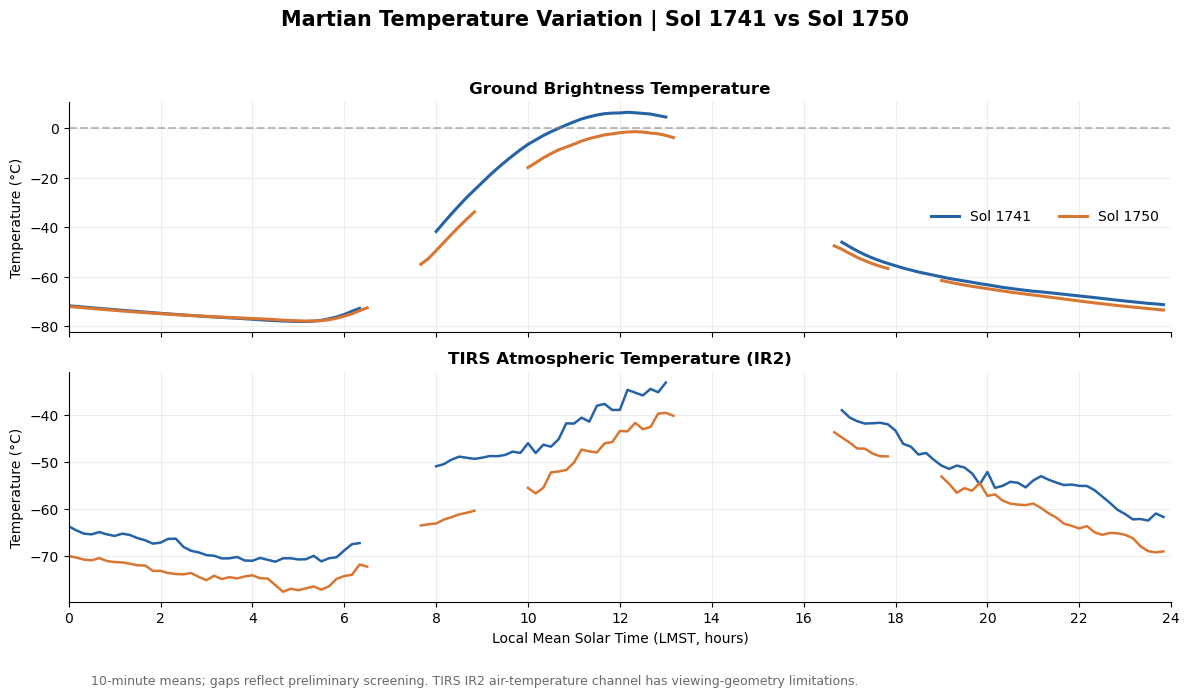

In [29]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

# Consistent colors for the two sols
colors = {
    1741: "#2563A6",
    1750: "#D97732"
}

datasets = [
    (1741, ten1741),
    (1750, ten1750)
]

for sol, data in datasets:

    time = data["LMST_HOURS"]

    # Upper panel: Ground brightness temperature
    axes[0].plot(
        time, data["GROUND_TEMP_C"],
        color=colors[sol],
        linewidth=2.2,
        label=f"Sol {sol}"
    )

    # Lower panel: TIRS air temperature
    axes[1].plot(
        time, data["AIR_TEMP_C"],
        color=colors[sol],
        linewidth=1.8,
        label=f"Sol {sol}"
    )

axes[0].set_title(
    "Ground Brightness Temperature",
    fontweight="bold"
)
axes[0].set_ylabel("Temperature (°C)")
axes[0].axhline(0, color="gray", linestyle="--", alpha=0.5)

axes[1].set_title(
    "TIRS Atmospheric Temperature (IR2)",
    fontweight="bold"
)
axes[1].set_ylabel("Temperature (°C)")
axes[1].set_xlabel("Local Mean Solar Time (LMST, hours)")

for ax in axes:
    ax.grid(alpha=0.22)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].legend(ncol=2, frameon=False)

axes[1].set_xlim(0, 24)
axes[1].set_xticks(range(0, 25, 2))

fig.suptitle(
    "Martian Temperature Variation | Sol 1741 vs Sol 1750",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.08, 0.015,
    "10-minute means; gaps reflect preliminary screening. "
    "TIRS IR2 air-temperature channel has viewing-geometry limitations.",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

plt.savefig(
    "Mars_Temperature_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()